# Co-clustering with the ordinal latent block model (OLBM)

The ordinal latent block model arranges each voter in **one group** and each item in
**one block**, so that the votes of a group on a block look alike; the votes of a
co-cluster follow a latent normal opinion cut into the five scores (Corneli, Bouveyron
and Latouche 2020). This notebook runs a full inference with `LatentBlockModel`:

1. load the votes;
2. choose the number of groups and of blocks with the integrated likelihood;
3. estimate the model from a spectral start, and compare with random starts;
4. read the result and its provenance;
5. draw it: co-clusters, sorted matrix, agreement between groups, memberships;
6. use the NetworkX graphs as data.

The data are **synthetic** (see `data/make_data.py`). Requirements:
`pip install "civiqhub-selene[viz]"`, run from the `examples/` folder.

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
from loading import planted_blocks, planted_groups, read_votes

from civiqhub_selene import viz
from civiqhub_selene.blocks import LatentBlockModel, RandomStart, SpectralStart, select_shape

plt.rcParams["figure.dpi"] = 90

## 1. Load the votes

In [2]:
votes = read_votes("data/consultation.votes.csv")
planted = planted_groups(votes, "data/consultation.voters.csv")
planted_items = planted_blocks(votes, "data/consultation.items.csv")
print(votes)

VoteMatrix(240 voters x 24 items, 2746 votes, 5 levels)
73.2% of the 5760 cells shown, 65.1% of the shown cells voted


## 2. Choose the shape

`select_shape` estimates the model at every shape of a grid (number of groups $Q$,
number of blocks $L$), here from a spectral start, and compares the shapes by the
**integrated completed likelihood** (ICL, Biernacki, Celeux and Govaert 2000): the
classified log-likelihood minus a penalty for the parameters. Larger is better. It
returns the model at the best shape; its `selection` keeps the score of every shape.

In [3]:
chosen = select_shape(
    votes,
    LatentBlockModel(n_starts=3, initialization=SpectralStart()),
    n_groups=(2, 3, 4, 5),
    n_blocks=(2, 3, 4),
    seed=0,
)
selection = chosen.value.selection
print(selection)
best = selection.best
print(f"best shape: {best[0]} groups x {best[1]} blocks")

Selection(integrated_likelihood: 3 groups x 3 blocks among 12 shapes)
groups \ blocks             2             3             4
2                   -6295.41      -5936.96      -5964.91 
3                   -6230.95      -5546.59*     -5579.66 
4                   -6258.53      -5584.83      -5627.42 
5                   -6301.20      -5622.26      -5696.81 
best shape: 3 groups x 3 blocks


The greedy search of the LBM note (Algorithm 4) starts from the smallest shape and adds
a group or a block while the score improves: it visits fewer shapes (the others read
`nan`) and finds the same one here.

In [4]:
greedy = select_shape(
    votes,
    LatentBlockModel(n_starts=3, initialization=SpectralStart()),
    n_groups=(2, 3, 4, 5),
    n_blocks=(2, 3, 4),
    search="greedy",
    seed=0,
).value.selection
print(greedy)

Selection(integrated_likelihood: 3 groups x 3 blocks among 12 shapes)
groups \ blocks             2             3             4
2                   -6295.41      -5936.96      -5964.91 
3                   -6230.95      -5546.59*     -5579.66 
4                        nan      -5584.83           nan 
5                        nan           nan           nan 


## 3. Estimate the model

The model is a frozen value: its settings are its fields, and `estimate` takes an
explicit seed. Each start begins from the arrangement of its `initialization`. To see
what the start changes, run twenty single starts of each kind and count how many reach
the best objective found, and in how many iterations.

In [5]:
n_groups, n_blocks = best
runs = {}
for name, initialization in (("random", RandomStart()), ("spectral", SpectralStart())):
    model = LatentBlockModel(
        n_groups=n_groups, n_blocks=n_blocks, n_starts=1, initialization=initialization
    )
    runs[name] = [model.estimate(votes, seed=seed).value for seed in range(20)]

top = max(value.objective for values in runs.values() for value in values)
for name, values in runs.items():
    reached = np.mean([value.objective > top - 1e-3 for value in values])
    iterations = np.mean([value.history.n_iterations for value in values])
    worst = min(value.objective for value in values)
    print(
        f"{name:<9} reach the best objective in {reached:4.0%} of the starts, "
        f"{iterations:4.1f} iterations on average, worst {worst:8.1f}"
    )

random    reach the best objective in  85% of the starts, 12.1 iterations on average, worst  -6681.8
spectral  reach the best objective in 100% of the starts,  5.8 iterations on average, worst  -5429.1


Every spectral start reaches the best objective, in fewer iterations; some random starts
stop at a worse local optimum, which more starts would have to make up for. The final
model keeps the default of six starts, from the spectral arrangement.

In [6]:
model = LatentBlockModel(n_groups=n_groups, n_blocks=n_blocks, initialization=SpectralStart())
result = model.estimate(votes, seed=0)
value = result.value
print(result)

Result(latent_block_model 0.1.0)
SingleCoclustering(240 voters in 3 groups x 24 items in 3 blocks)
groups of 100, 60, 80 voters; blocks of 8, 8, 8 items
group 0 x block 0: vote rate 0.69, typical score 0, 412 votes
group 0 x block 1: vote rate 0.84, typical score +2, 509 votes
group 0 x block 2: vote rate 0.46, typical score -2, 279 votes
group 1 x block 0: vote rate 0.81, typical score +2, 272 votes
group 1 x block 1: vote rate 0.39, typical score 0, 135 votes
group 1 x block 2: vote rate 0.41, typical score 0, 136 votes
group 2 x block 0: vote rate 0.70, typical score -2, 331 votes
group 2 x block 1: vote rate 0.57, typical score -2, 264 votes
group 2 x block 2: vote rate 0.87, typical score +2, 408 votes


## 4. Read the result

A `Result` carries the value and its provenance: the method and its version, every
setting (the start included), the seed and the fingerprint of the input. The value is a
`SingleCoclustering`: groups, blocks, the table of the co-clusters and the integrated
likelihood.

In [7]:
provenance = result.provenance
print(provenance.method, "| seed", provenance.seed, "| input", provenance.input_fingerprint)
print("initialization:", dict(provenance.parameters)["initialization"])
print("fingerprint of the computation:", result.fingerprint())
print()
print(value.groups)
print(value.blocks)
print(value[0, 0])

latent_block_model 0.1.0 | seed 0 | input 9ebc1320b9021137
initialization: (('type', 'SpectralStart'), ('encoding', 'states'), ('leverage_threshold', 0.0), ('n_init', 10), ('project', True), ('regularization', 1.0))
fingerprint of the computation: 73fd7991fde43e2d

Partition(240 voters in 3 mixed groups: 100, 60, 80)
Partition(24 items in 3 mixed blocks: 8, 8, 8)
Cocluster(group=0, block=0, vote_rate=0.692, typical_score=+0, n_votes=412)


## 5. Draw it

**Co-clusters as a graph.** Groups on the left, blocks on the right; the edge of a
co-cluster is coloured by the mean score of its votes (orange: disagreement, blue:
agreement) and its width follows the vote rate.

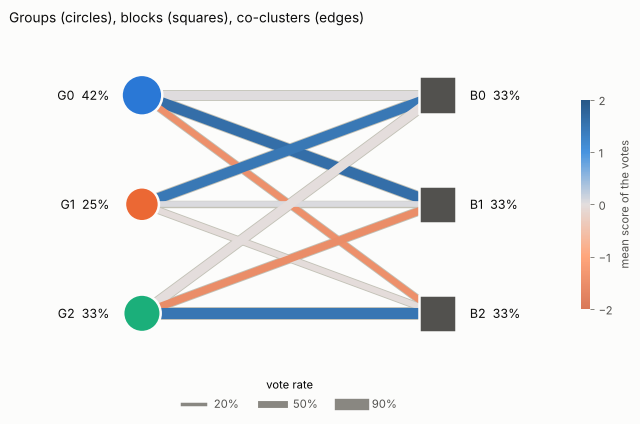

In [8]:
viz.draw_coclustering(value)
plt.show()

**The sorted matrix.** The same votes as above, with voters sorted by group and items by
block: each rectangle is a co-cluster.

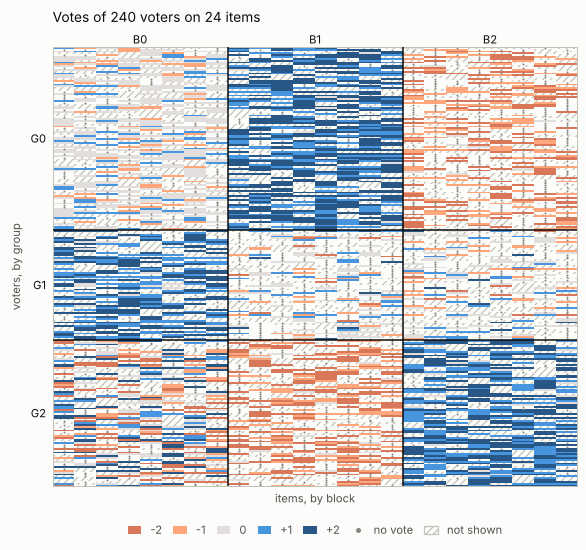

In [9]:
viz.plot_vote_matrix(votes, value)
plt.show()

**Agreement between groups and memberships.** On the left, the agreement of two groups:
one minus the total variation distance between their votes, averaged over the blocks.
On the right, each voter is placed between the groups by its memberships: under a single
membership, each sits on its group.

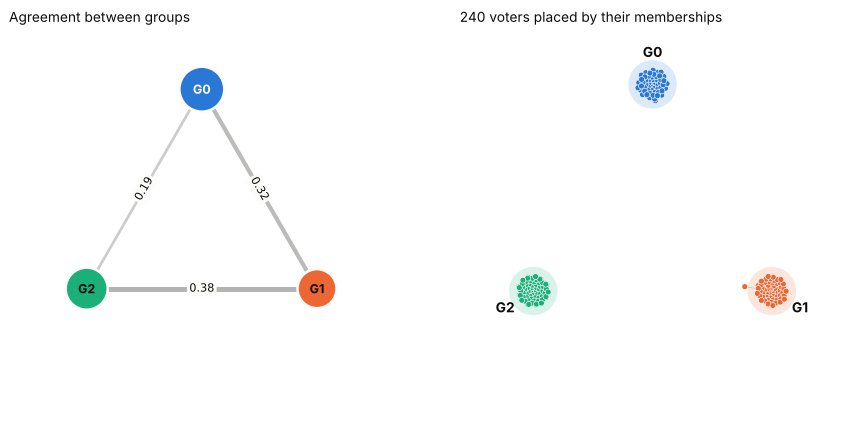

In [10]:
figure, (left, right) = plt.subplots(1, 2, figsize=(10, 4.6), layout="constrained")
viz.draw_groups(value, ax=left)
viz.draw_memberships(value, ax=right)
plt.show()

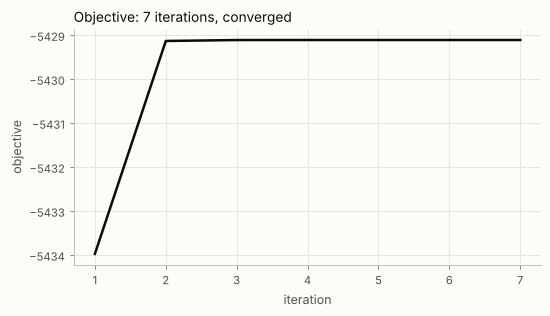

In [11]:
viz.plot_history(value)
plt.show()

## 6. The graphs as data

Each figure reads a NetworkX graph from `civiqhub_selene.viz.graphs`. The graphs carry
the numbers of the result as attributes: they can be exported, or used for other
computations.

In [12]:
graph = viz.coclustering_graph(value)
for group, block, data in sorted(graph.edges(data=True)):
    print(
        f"{graph.nodes[group]['label']} x {graph.nodes[block]['label']}: "
        f"vote rate {data['vote_rate']:.2f}, mean score {data['mean_score']:+.2f}, "
        f"latent opinion {data['latent_mean']:.2f} +/- {data['latent_spread']:.2f}"
    )

G0 x B0: vote rate 0.69, mean score +0.02, latent opinion 3.02 +/- 0.53
G0 x B1: vote rate 0.84, mean score +1.62, latent opinion 4.70 +/- 0.57
G0 x B2: vote rate 0.46, mean score -1.47, latent opinion 1.48 +/- 0.59
G1 x B0: vote rate 0.81, mean score +1.46, latent opinion 4.54 +/- 0.67
G1 x B1: vote rate 0.39, mean score +0.05, latent opinion 3.05 +/- 0.99
G1 x B2: vote rate 0.41, mean score -0.04, latent opinion 2.95 +/- 0.99
G2 x B0: vote rate 0.70, mean score -0.02, latent opinion 2.97 +/- 2.24
G2 x B1: vote rate 0.57, mean score -1.53, latent opinion 1.34 +/- 0.72
G2 x B2: vote rate 0.87, mean score +1.50, latent opinion 4.57 +/- 0.64


In [13]:
agreement = viz.group_graph(value)
closest = max(agreement.edges(data="agreement"), key=lambda edge: edge[2])
print("closest groups:", closest[0], closest[1], f"agreement {closest[2]:.2f}")
exported = nx.node_link_data(agreement, edges="edges")
print("exported as node-link data:", sorted(exported))

closest groups: ('group', 1) ('group', 2) agreement 0.38
exported as node-link data: ['directed', 'edges', 'graph', 'multigraph', 'nodes']


The votes of a co-cluster can also be handed to the ordinal family, for example to
count them:

In [14]:
grouped = votes.group_by(value.groups, value.blocks)
print(grouped.vote_counts(0, 2))

VoteCounts(group 0 x block 2: 144, 123, 12, 0, 0; 279 votes)


**References.** Govaert and Nadif (2003), *Clustering with block mixture models*, Pattern
Recognition 36(2). Biernacki, Celeux and Govaert (2000), *Assessing a mixture model for
clustering with the integrated completed likelihood*, IEEE TPAMI 22(7). Corneli,
Bouveyron and Latouche (2020), *Co-clustering of ordinal data via latent continuous random
variables and not missing at random entries*, JCGS 29(4).